# Multi-Class Brain CT Hemorrhage Segmentation (2.5D DeepLabV3+)
## Complete, Self-Contained End-to-End Training & Evaluation Pipeline

### Research Objectives
1. **Multi-Class Intracranial Hemorrhage (ICH) Segmentation**:
   - Delineate **5 distinct hemorrhage types** + Background (6 output classes in total):
     - **Class 0: Background** (Healthy brain parenchyma, skull, CSF)
     - **Class 1: IPH** (Intraparenchymal Hemorrhage — hyperdense collection inside parenchyma)
     - **Class 2: SAH** (Subarachnoid Hemorrhage — subtle, thin bleed in sulci / basal cisterns)
     - **Class 3: EDH** (Epidural Hemorrhage — biconvex lens-shaped collection outside dura)
     - **Class 4: SDH** (Subdural Hemorrhage — crescent-shaped bleed crossing sutures)
     - **Class 5: IVH** (Intraventricular Hemorrhage — blood pooling inside ventricles)
2. **2.5D Multi-Window Representation**:
   - 3 consecutive CT slices ($z-1, z, z+1$) each rendered across **3 clinical Hounsfield Unit (HU) windows**:
     - **Brain Window:** WL = 40, WW = 80 $
ightarrow [0, 80]$ HU
     - **Subdural Window:** WL = 75, WW = 215 $
ightarrow [-32.5, 182.5]$ HU
     - **Bone Window:** WL = 400, WW = 1800 $
ightarrow [-500, 1300]$ HU
   - Produces a **9-channel input tensor** $[B, 9, H, W]$ predicting the centre slice mask $[B, H, W]$.
3. **DeepLabV3+ with ResNet34 Backbone**:
   - ImageNet pretrained weights adapted for 9 channels.
   - ASPP decoder dropout $p \ge 0.2$ validated for Monte Carlo Dropout uncertainty estimation.
4. **Data Isolation & Reproducibility**:
   - Patient-level stratified split: **134 training, 28 validation, and 30 development holdout volumes** (192 total).
   - Strict guarantee of zero patient and zero volume leakage.
   - Best checkpoint saved strictly by **Validation Macro Dice across the 5 hemorrhage classes** (excluding background).


In [1]:
# =========================================================================
# 1. SETUP & HARDWARE VERIFICATION
# =========================================================================
print('[SETUP 1/8] Starting Python imports...', flush=True)
import os
import sys
import time
import math
import random
from pathlib import Path
from collections import defaultdict, OrderedDict
from typing import Dict, List, Tuple, Optional, Any

print('[SETUP 2/8] Loading NumPy and pandas...', flush=True)
import numpy as np
import pandas as pd
print('[SETUP 3/8] Loading Matplotlib...', flush=True)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm
print('[SETUP 4/8] Loading PyTorch...', flush=True)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms.functional as TF
print('[SETUP 5/8] Loading medical imaging libraries...', flush=True)

import nibabel as nib
print('[SETUP 6/8] Loading segmentation_models_pytorch...', flush=True)
import segmentation_models_pytorch as smp


print('[SETUP 7/8] Imports complete; checking hardware...', flush=True)
# Hardware & CUDA Diagnostics
print("=== ENVIRONMENT DIAGNOSTICS ===", flush=True)
print(f"Python Version    : {sys.version.split()[0]}", flush=True)
print(f"PyTorch Version   : {torch.__version__}", flush=True)
print(f"CUDA Available    : {torch.cuda.is_available()}", flush=True)
if torch.cuda.is_available():
    print(f"Device Name       : {torch.cuda.get_device_name(0)}", flush=True)
    print(f"VRAM Available    : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB", flush=True)
    print(f"CUDA Arch / Cap   : {torch.cuda.get_device_capability(0)}", flush=True)
else:
    print("WARNING: CUDA is not available. Execution will fall back to CPU (slower).", flush=True)
print('[SETUP 8/8] Setup cell finished.', flush=True)


[SETUP 1/8] Starting Python imports...
[SETUP 2/8] Loading NumPy and pandas...
[SETUP 3/8] Loading Matplotlib...
[SETUP 4/8] Loading PyTorch...
[SETUP 5/8] Loading medical imaging libraries...
[SETUP 6/8] Loading segmentation_models_pytorch...
[SETUP 7/8] Imports complete; checking hardware...
=== ENVIRONMENT DIAGNOSTICS ===
Python Version    : 3.14.7
PyTorch Version   : 2.11.0+cu128
CUDA Available    : True
Device Name       : NVIDIA RTX PRO 5000 Blackwell
VRAM Available    : 47.79 GB
CUDA Arch / Cap   : (12, 0)
[SETUP 8/8] Setup cell finished.


In [2]:
# =========================================================================
# 2. GLOBAL PATHS & HYPERPARAMETERS CONFIGURATION
# =========================================================================
# Adjust dataset path if running on Colab or Kaggle (e.g. '/content/Dataset' or '/kaggle/input/...')
# Resolve paths from either the repository root or the week4 notebook directory.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "Dataset").is_dir() and (PROJECT_ROOT.parent / "Dataset").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_DIR = str(PROJECT_ROOT / "Dataset")
OUTPUT_DIR = str(PROJECT_ROOT / "outputs")
SPLIT_DIR = str(PROJECT_ROOT / "data_splits")

# Hardware & Runtime
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = True if torch.cuda.is_available() else False  # Mixed precision (fp16)
NUM_WORKERS = 4 if os.name != "nt" else 0               # 0 on Windows, 4 on Linux/GPU cluster

# Model Architecture
ARCHITECTURE = "DeepLabV3Plus"
ENCODER_NAME = "resnet34"
ENCODER_WEIGHTS = "imagenet"
IN_CHANNELS = 9                  # 3 consecutive slices x 3 CT windows
NUM_CLASSES = 6                  # Background (0) + 5 hemorrhage types (1..5)
DECODER_DROPOUT = 0.2            # Must be >= 0.2 for MC Dropout compliance

# Training Hyperparameters
BATCH_SIZE = 8                   # Recommended: 4-8 on modern GPUs (e.g. RTX 3050, 3080, T4, A100)
NUM_EPOCHS = 35                  # Total training epochs
LEARNING_RATE = 3e-4             # Initial AdamW learning rate
MIN_LR = 1e-5                    # Minimum learning rate for cosine scheduler
WEIGHT_DECAY = 1e-4              # Optimizer L2 regularization
GRAD_CLIP_NORM = 1.0             # Gradient clipping threshold
EARLY_STOPPING_PATIENCE = 12     # Epochs without validation macro Dice improvement
FILTER_EMPTY_SLICES_PROB = 0.35  # Fraction of background-only slices to skip during training

# Loss & Imbalance Parameters
ALPHA_CE = 1.0                   # Weight for Weighted Cross-Entropy
BETA_DICE = 1.0                  # Weight for Multiclass Soft Dice Loss
WEIGHT_POWER = 0.5               # Square-root smoothed inverse class frequencies
MAX_CLASS_WEIGHT = 25.0          # Cap to prevent gradient explosion on tiny lesions

# Minority Slice Sampling Boost Factors
MINORITY_SAMPLING = {
    "enabled": True,
    "weight_edh": 4.0,           # Epidural Hemorrhage (rarest: 0.018% of voxels)
    "weight_sdh": 3.0,           # Subdural Hemorrhage (0.073% of voxels)
    "weight_sah": 3.0,           # Subarachnoid Hemorrhage (0.047% of voxels)
    "weight_iph": 2.0,           # Intraparenchymal Hemorrhage
    "weight_ivh": 2.0,           # Intraventricular Hemorrhage
    "weight_bg": 1.0,            # Background slice baseline
}

# Augmentations (Preserves tissue window integrity: intensity shifts strictly <= 20 HU)
AUGMENTATION = {
    "hflip_prob": 0.5,
    "rotate_deg": 15.0,
    "intensity_jitter_hu": 20.0,
}

RANDOM_SEED = 42
DETERMINISTIC = True

# Create necessary directories
os.makedirs(SPLIT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "checkpoints"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "metrics"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "figures"), exist_ok=True)

# Set deterministic reproducibility seeds
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(RANDOM_SEED)
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    torch.backends.cudnn.benchmark = not DETERMINISTIC
print(f"[REPRODUCIBILITY] Random seeds locked to {RANDOM_SEED}")
print(f"[CONFIGURATION] Output directory: {OUTPUT_DIR} | Batch size: {BATCH_SIZE} | Epochs: {NUM_EPOCHS}")


[REPRODUCIBILITY] Random seeds locked to 42
[CONFIGURATION] Output directory: c:\Users\whate\Documents\Brain CT Hemorrage Detection\outputs | Batch size: 8 | Epochs: 35


## 3. Explicit BHSD Label Mapping to Target Classes

**Critical Medical Note:**
In the raw BHSD dataset, integer class IDs do **not** match the requested target order.
- **Raw BHSD IDs:** `0`: Background, `1`: Epidural, `2`: Intraparenchymal, `3`: Intraventricular, `4`: Subarachnoid, `5`: Subdural.
- **Target Ordering:** `0`: Background, `1`: IPH, `2`: SAH, `3`: EDH, `4`: SDH, `5`: IVH.

We use an explicit bijective mapping table:
$$\text{Raw BHSD } 0 \rightarrow 0 \text{ (Background)}$$
$$\text{Raw BHSD } 1 \rightarrow 3 \text{ (EDH)}$$
$$\text{Raw BHSD } 2 \rightarrow 1 \text{ (IPH)}$$
$$\text{Raw BHSD } 3 \rightarrow 5 \text{ (IVH)}$$
$$\text{Raw BHSD } 4 \rightarrow 2 \text{ (SAH)}$$
$$\text{Raw BHSD } 5 \rightarrow 4 \text{ (SDH)}$$


In [3]:
# =========================================================================
# 3. CLASS MAPPINGS & COLOR PALETTES
# =========================================================================
RAW_BHSD_CLASSES = {
    0: "background",
    1: "epidural",
    2: "intraparenchymal",
    3: "intraventricular",
    4: "subarachnoid",
    5: "subdural",
}

BHSD_TO_TARGET = {
    0: 0,  # Background      -> Background
    1: 3,  # Epidural        -> EDH (Class 3)
    2: 1,  # Intraparenchymal-> IPH (Class 1)
    3: 5,  # Intraventricular -> IVH (Class 5)
    4: 2,  # Subarachnoid    -> SAH (Class 2)
    5: 4,  # Subdural        -> SDH (Class 4)
}

TARGET_NAMES = ["Background", "IPH", "SAH", "EDH", "SDH", "IVH"]

# High-contrast clinical overlay colors:
# 0: Transparent, 1: Red (IPH), 2: Cyan (SAH), 3: Yellow (EDH), 4: Orange (SDH), 5: Magenta (IVH)
CLASS_COLORS = [
    (0.0, 0.0, 0.0, 0.0),       # 0: BG (transparent)
    (0.9, 0.1, 0.1, 0.65),      # 1: IPH (hyperdense red)
    (0.1, 0.8, 0.8, 0.70),      # 2: SAH (cyan)
    (1.0, 0.85, 0.0, 0.75),     # 3: EDH (bright yellow)
    (1.0, 0.5, 0.0, 0.70),      # 4: SDH (orange)
    (0.8, 0.1, 0.8, 0.70),      # 5: IVH (magenta)
]

OVERLAY_CMAP = ListedColormap(CLASS_COLORS)
print("[CLASSES] Target Classes Defined:", {i: name for i, name in enumerate(TARGET_NAMES)})


[CLASSES] Target Classes Defined: {0: 'Background', 1: 'IPH', 2: 'SAH', 3: 'EDH', 4: 'SDH', 5: 'IVH'}


## 4. Patient-Level Stratified Dataset Split (Zero Leakage)

Across the 192 BHSD volumes, there are **191 unique patients** (patient `ID_2db7ee14` has two scans).
To prevent **patient data leakage**, scans belonging to the same patient are strictly kept within the same partition.
We stratify by hemorrhage class rarity into:
- **134 volumes** for training ($\sim 70\%$)
- **28 volumes** for validation ($\sim 15\%$)
- **30 volumes** for development holdout ($\sim 15\%$)


In [4]:
# =========================================================================
# 4. PATIENT-LEVEL ZERO-LEAKAGE STRATIFIED SPLIT GENERATION
# =========================================================================
def extract_patient_id(filename: str) -> str:
    parts = filename.replace(".nii.gz", "").split("_")
    if len(parts) >= 2 and parts[0] == "ID":
        return parts[1]
    return parts[0]

def inspect_and_generate_splits(dataset_dir: str, split_dir: str, seed: int = 42):
    img_dir = os.path.join(dataset_dir, "labeled", "images")
    gt_dir = os.path.join(dataset_dir, "labeled", "ground_truths")
    
    files = sorted([f for f in os.listdir(img_dir) if f.endswith(".nii.gz")])
    print(f"Discovered {len(files)} NIfTI image-mask pairs in {dataset_dir}...")

    manifest_records = []
    for f in tqdm(files, desc="Scanning NIfTI Volumes"):
        p_id = extract_patient_id(f)
        gt_path = os.path.join(gt_dir, f)
        gt_arr = np.asanyarray(nib.load(gt_path).dataobj)
        shape = list(gt_arr.shape)
        unique_raw = [int(c) for c in np.unique(gt_arr)]
        unique_target = [BHSD_TO_TARGET[c] for c in unique_raw]

        manifest_records.append({
            "filename": f,
            "patient_id": p_id,
            "num_slices": shape[2],
            "height": shape[0],
            "width": shape[1],
            "raw_classes": unique_raw,
            "target_classes": unique_target,
            "has_edh": 1 in unique_raw,
            "has_iph": 2 in unique_raw,
            "has_ivh": 3 in unique_raw,
            "has_sah": 4 in unique_raw,
            "has_sdh": 5 in unique_raw,
        })

    df = pd.DataFrame(manifest_records)
    rng = np.random.RandomState(seed)

    # Group by patient_id
    patient_info = []
    for p_id, group in df.groupby("patient_id"):
        files_p = group["filename"].tolist()
        has_edh = group["has_edh"].any()
        has_sdh = group["has_sdh"].any()
        has_ivh = group["has_ivh"].any()
        has_sah = group["has_sah"].any()
        has_iph = group["has_iph"].any()

        # Stratification priority by rarity: EDH > SDH > IVH > SAH > IPH
        if has_edh:
            strat_key = "EDH"
        elif has_sdh:
            strat_key = "SDH"
        elif has_ivh:
            strat_key = "IVH"
        elif has_sah:
            strat_key = "SAH"
        elif has_iph:
            strat_key = "IPH"
        else:
            strat_key = "None"

        patient_info.append({
            "patient_id": p_id,
            "filenames": files_p,
            "num_volumes": len(files_p),
            "strat_key": strat_key,
        })

    rng.shuffle(patient_info)
    buckets = defaultdict(list)
    for p in patient_info:
        buckets[p["strat_key"]].append(p)

    train_p, val_p, dev_p = [], [], []
    train_c, val_c, dev_c = 0, 0, 0
    n_train, n_val, n_dev = 134, 28, 30

    for key in ["EDH", "SDH", "IVH", "SAH", "IPH", "None"]:
        for p in buckets[key]:
            v_cnt = p["num_volumes"]
            train_def = n_train - train_c
            val_def = n_val - val_c
            dev_def = n_dev - dev_c

            if (val_c / n_val) <= (dev_c / n_dev) and val_def >= v_cnt and val_c < n_val:
                val_p.append(p)
                val_c += v_cnt
            elif (dev_c / n_dev) <= (train_c / n_train) and dev_def >= v_cnt and dev_c < n_dev:
                dev_p.append(p)
                dev_c += v_cnt
            elif train_def >= v_cnt:
                train_p.append(p)
                train_c += v_cnt
            elif val_def >= v_cnt:
                val_p.append(p)
                val_c += v_cnt
            elif dev_def >= v_cnt:
                dev_p.append(p)
                dev_c += v_cnt
            else:
                train_p.append(p)
                train_c += v_cnt

    train_files = [f for p in train_p for f in p["filenames"]]
    val_files = [f for p in val_p for f in p["filenames"]]
    dev_files = [f for p in dev_p for f in p["filenames"]]

    # Zero leakage assertions
    assert len(train_files) == 134 and len(val_files) == 28 and len(dev_files) == 30
    assert len(set(train_files) & set(val_files)) == 0, "Volume overlap between train and val!"
    assert len(set(train_files) & set(dev_files)) == 0, "Volume overlap between train and dev!"
    assert len(set(val_files) & set(dev_files)) == 0, "Volume overlap between val and dev!"

    p_train = {extract_patient_id(f) for f in train_files}
    p_val = {extract_patient_id(f) for f in val_files}
    p_dev = {extract_patient_id(f) for f in dev_files}
    assert len(p_train & p_val) == 0, "Patient overlap between train and val!"
    assert len(p_train & p_dev) == 0, "Patient overlap between train and dev!"
    assert len(p_val & p_dev) == 0, "Patient overlap between val and dev!"

    # Save manifests
    train_df = df[df["filename"].isin(train_files)].copy()
    val_df = df[df["filename"].isin(val_files)].copy()
    dev_df = df[df["filename"].isin(dev_files)].copy()

    train_path = os.path.join(split_dir, "train_manifest.csv")
    val_path = os.path.join(split_dir, "val_manifest.csv")
    dev_path = os.path.join(split_dir, "dev_manifest.csv")

    train_df.to_csv(train_path, index=False)
    val_df.to_csv(val_path, index=False)
    dev_df.to_csv(dev_path, index=False)

    print(f"\n[SUCCESS] Split Manifests Generated with ZERO Leakage:")
    print(f"  Train : {len(train_df)} volumes | Total slices: {train_df['num_slices'].sum()} | Path: {train_path}")
    print(f"  Val   : {len(val_df)} volumes | Total slices: {val_df['num_slices'].sum()} | Path: {val_path}")
    print(f"  Dev   : {len(dev_df)} volumes | Total slices: {dev_df['num_slices'].sum()} | Path: {dev_path}")
    return train_path, val_path, dev_path

TRAIN_MANIFEST, VAL_MANIFEST, DEV_MANIFEST = inspect_and_generate_splits(DATASET_DIR, SPLIT_DIR, RANDOM_SEED)


Discovered 192 NIfTI image-mask pairs in c:\Users\whate\Documents\Brain CT Hemorrage Detection\Dataset...


Scanning NIfTI Volumes:   0%|          | 0/192 [00:00<?, ?it/s]


[SUCCESS] Split Manifests Generated with ZERO Leakage:
  Train : 134 volumes | Total slices: 4503 | Path: c:\Users\whate\Documents\Brain CT Hemorrage Detection\data_splits\train_manifest.csv
  Val   : 28 volumes | Total slices: 924 | Path: c:\Users\whate\Documents\Brain CT Hemorrage Detection\data_splits\val_manifest.csv
  Dev   : 30 volumes | Total slices: 977 | Path: c:\Users\whate\Documents\Brain CT Hemorrage Detection\data_splits\dev_manifest.csv


## 5. CT Windowing & 2.5D Multi-Slice Input Assembly

To maximize lesion visibility, each 2D CT slice in Hounsfield Units is windowed across:
1. **Brain Window:** $\text{WL}=40, \text{WW}=80 \rightarrow [0, 80]$ HU
2. **Subdural Window:** $\text{WL}=75, \text{WW}=215 \rightarrow [-32.5, 182.5]$ HU
3. **Bone Window:** $\text{WL}=400, \text{WW}=1800 \rightarrow [-500, 1300]$ HU

For each center slice $z$:
We extract slice $z-1$, slice $z$, and slice $z+1$ (with boundary edge replication).
Applying all 3 windows yields $3 \times 3 = \mathbf{9 \text{ input channels}}$.
Each channel is normalized using ImageNet channel statistics.


In [5]:
# =========================================================================
# 5. CT WINDOWING, 2.5D ASSEMBLY & NORMALIZATION
# =========================================================================
WINDOW_SPECS = {
    "brain": (40.0, 80.0),
    "subdural": (75.0, 215.0),
    "bone": (400.0, 1800.0),
}

IMAGENET_MEAN_9CH = [0.485, 0.456, 0.406] * 3
IMAGENET_STD_9CH  = [0.229, 0.224, 0.225] * 3

def apply_window(img_hu: np.ndarray, wl: float, ww: float) -> np.ndarray:
    lower = wl - (ww / 2.0)
    upper = wl + (ww / 2.0)
    windowed = np.clip(img_hu, lower, upper)
    normalized = (windowed - lower) / (upper - lower)
    return normalized.astype(np.float32)

def apply_3_windows(img_hu: np.ndarray) -> np.ndarray:
    w_brain = apply_window(img_hu, *WINDOW_SPECS["brain"])
    w_subdural = apply_window(img_hu, *WINDOW_SPECS["subdural"])
    w_bone = apply_window(img_hu, *WINDOW_SPECS["bone"])
    return np.stack([w_brain, w_subdural, w_bone], axis=0)

def build_25d_input(s_prev: np.ndarray, s_curr: np.ndarray, s_next: np.ndarray) -> np.ndarray:
    st_prev = apply_3_windows(s_prev)
    st_curr = apply_3_windows(s_curr)
    st_next = apply_3_windows(s_next)
    return np.concatenate([st_prev, st_curr, st_next], axis=0)

def normalize_channels(arr: np.ndarray) -> np.ndarray:
    c = arr.shape[0]
    mean = IMAGENET_MEAN_9CH if c == 9 else [0.485, 0.456, 0.406]
    std = IMAGENET_STD_9CH if c == 9 else [0.229, 0.224, 0.225]
    norm_arr = np.empty_like(arr, dtype=np.float32)
    for i in range(c):
        norm_arr[i] = (arr[i] - mean[i]) / std[i]
    return norm_arr

class CTTransform:
    def __init__(self, is_training: bool = True, hflip_prob: float = 0.5, rotate_deg: float = 15.0, intensity_jitter_hu: float = 20.0):
        self.is_training = is_training
        self.hflip_prob = hflip_prob
        self.rotate_deg = rotate_deg
        self.intensity_jitter_hu = min(intensity_jitter_hu, 30.0)

    def __call__(self, slices_hu: np.ndarray, mask: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        slices_hu = slices_hu.copy()
        mask = mask.copy()

        if self.is_training:
            # 1. Conservative intensity jitter in HU space (bounded to <= 20 HU)
            if self.intensity_jitter_hu > 0 and np.random.rand() > 0.5:
                delta = np.random.uniform(-self.intensity_jitter_hu, self.intensity_jitter_hu)
                slices_hu = slices_hu + delta

            # 2. Random horizontal flip (brain anatomy is bilateral)
            if np.random.rand() < self.hflip_prob:
                slices_hu = np.flip(slices_hu, axis=2).copy()
                mask = np.flip(mask, axis=1).copy()

            # 3. Modest rotation (+/- 15 degrees)
            if self.rotate_deg > 0 and np.random.rand() > 0.5:
                angle = float(np.random.uniform(-self.rotate_deg, self.rotate_deg))
                t_slices = torch.from_numpy(slices_hu).unsqueeze(0)
                t_mask = torch.from_numpy(mask).unsqueeze(0).unsqueeze(0).float()
                
                t_slices = TF.rotate(t_slices, angle, interpolation=TF.InterpolationMode.BILINEAR)
                t_mask = TF.rotate(t_mask, angle, interpolation=TF.InterpolationMode.NEAREST)
                
                slices_hu = t_slices.squeeze(0).numpy()
                mask = t_mask.squeeze(0).squeeze(0).long().numpy()

        stacked_9ch = build_25d_input(slices_hu[0], slices_hu[1], slices_hu[2])
        norm_9ch = normalize_channels(stacked_9ch)
        return norm_9ch, mask.astype(np.int64)

print("[PREPROCESSING] 2.5D CT 9-channel transform pipeline initialized.")


[PREPROCESSING] 2.5D CT 9-channel transform pipeline initialized.


## 6. PyTorch Dataset, In-Memory Volume Cache & Minority Sampler

To make 2.5D slice loading fast on modern GPUs:
- **`VolumeCache`**: Keeps recently decompressed NIfTI volumes in RAM using memory-efficient types (`np.int16` for CT images and `np.uint8` for masks), reducing RAM usage by 50% while eliminating redundant disk I/O.
- **`create_class_aware_sampler`**: Generates sampling weights per slice so rare hemorrhage classes (**SDH, SAH, EDH**) are sampled more frequently during training, mitigating extreme foreground class starvation.


In [6]:
# =========================================================================
# 6. PYTORCH DATASET, VOLUME CACHE & CLASS-AWARE SAMPLER
# =========================================================================
class VolumeCache:
    def __init__(self, capacity: int = 32):
        self.capacity = capacity
        self.cache: OrderedDict[str, Tuple[np.ndarray, np.ndarray]] = OrderedDict()

    def get(self, key: str) -> Optional[Tuple[np.ndarray, np.ndarray]]:
        if key in self.cache:
            self.cache.move_to_end(key)
            return self.cache[key]
        return None

    def put(self, key: str, value: Tuple[np.ndarray, np.ndarray]):
        if key in self.cache:
            self.cache.move_to_end(key)
        else:
            if len(self.cache) >= self.capacity:
                self.cache.popitem(last=False)
            self.cache[key] = value

class BrainCT25DDataset(Dataset):
    def __init__(self, manifest_csv: str, dataset_dir: str = "Dataset", transform=None, filter_empty_prob: float = 0.0):
        self.manifest = pd.read_csv(manifest_csv)
        self.dataset_dir = dataset_dir
        self.img_dir = os.path.join(dataset_dir, "labeled", "images")
        self.gt_dir = os.path.join(dataset_dir, "labeled", "ground_truths")
        self.transform = transform or CTTransform(is_training=False)
        self.cache = VolumeCache(capacity=32)
        self.slice_indices = []

        # Index all slices across all volumes
        for _, row in self.manifest.iterrows():
            fname = row["filename"]
            num_slices = int(row["num_slices"])
            gt_path = os.path.join(self.gt_dir, fname)
            gt_arr = np.asanyarray(nib.load(gt_path).dataobj)

            for z in range(num_slices):
                slice_gt = gt_arr[:, :, z]
                unique_raw = [int(c) for c in np.unique(slice_gt)]
                unique_target = [BHSD_TO_TARGET[c] for c in unique_raw]
                has_fg = any(c > 0 for c in unique_target)

                # Skip a portion of empty slices during training if specified
                if not has_fg and filter_empty_prob > 0:
                    if np.random.rand() < filter_empty_prob:
                        continue

                self.slice_indices.append({
                    "filename": fname,
                    "slice_idx": z,
                    "num_slices": num_slices,
                    "target_classes": unique_target,
                    "has_foreground": has_fg,
                    "has_edh": 3 in unique_target,
                    "has_iph": 1 in unique_target,
                    "has_sah": 2 in unique_target,
                    "has_sdh": 4 in unique_target,
                    "has_ivh": 5 in unique_target,
                })

    def __len__(self) -> int:
        return len(self.slice_indices)

    def _load_volume(self, fname: str) -> Tuple[np.ndarray, np.ndarray]:
        cached = self.cache.get(fname)
        if cached is not None:
            return cached

        img_path = os.path.join(self.img_dir, fname)
        gt_path = os.path.join(self.gt_dir, fname)

        img_nii = nib.load(img_path)
        gt_nii = nib.load(gt_path)

        # Store in int16 / uint8 to halve memory footprint
        img_int16 = np.round(img_nii.get_fdata(dtype=np.float32)).astype(np.int16)
        gt_raw = np.asanyarray(gt_nii.dataobj)

        target_gt = np.zeros(gt_raw.shape, dtype=np.uint8)
        for raw_c, target_c in BHSD_TO_TARGET.items():
            if target_c != 0:
                target_gt[gt_raw == raw_c] = target_c

        self.cache.put(fname, (img_int16, target_gt))
        return img_int16, target_gt

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, Dict[str, Any]]:
        meta = self.slice_indices[idx]
        fname = meta["filename"]
        z = meta["slice_idx"]
        num_slices = meta["num_slices"]

        img_vol, gt_vol = self._load_volume(fname)

        # 2.5D consecutive slice extraction with edge replication padding
        z_prev = max(0, z - 1)
        z_curr = z
        z_next = min(num_slices - 1, z + 1)

        s_prev = img_vol[:, :, z_prev]
        s_curr = img_vol[:, :, z_curr]
        s_next = img_vol[:, :, z_next]
        slices_hu = np.stack([s_prev, s_curr, s_next], axis=0).astype(np.float32)

        # Center slice target mask
        mask = gt_vol[:, :, z_curr].astype(np.int64)

        norm_9ch, processed_mask = self.transform(slices_hu, mask)
        t_img = torch.from_numpy(norm_9ch).float()
        t_mask = torch.from_numpy(processed_mask).long()

        has_classes = torch.zeros(6, dtype=torch.bool)
        for c in meta["target_classes"]:
            has_classes[c] = True

        sample_info = {
            "filename": fname,
            "slice_idx": z,
            "has_classes": has_classes,
        }
        return t_img, t_mask, sample_info

def create_class_aware_sampler(slice_indices: List[Dict[str, Any]], weights_dict: Dict[str, float]) -> WeightedRandomSampler:
    weights = []
    w_edh = weights_dict.get("weight_edh", 4.0)
    w_sdh = weights_dict.get("weight_sdh", 3.0)
    w_sah = weights_dict.get("weight_sah", 3.0)
    w_iph = weights_dict.get("weight_iph", 2.0)
    w_ivh = weights_dict.get("weight_ivh", 2.0)
    w_bg  = weights_dict.get("weight_bg", 1.0)

    for meta in slice_indices:
        t_classes = set(meta.get("target_classes", []))
        if 3 in t_classes:
            w = w_edh
        elif 4 in t_classes:
            w = w_sdh
        elif 2 in t_classes:
            w = w_sah
        elif 5 in t_classes:
            w = w_ivh
        elif 1 in t_classes:
            w = w_iph
        else:
            w = w_bg
        weights.append(w)

    weights_tensor = torch.as_tensor(weights, dtype=torch.double)
    return WeightedRandomSampler(weights=weights_tensor, num_samples=len(weights), replacement=True)

# Instantiate Datasets
train_transform = CTTransform(is_training=True, **AUGMENTATION)
val_transform = CTTransform(is_training=False)

train_dataset = BrainCT25DDataset(TRAIN_MANIFEST, DATASET_DIR, transform=train_transform, filter_empty_prob=FILTER_EMPTY_SLICES_PROB)
val_dataset = BrainCT25DDataset(VAL_MANIFEST, DATASET_DIR, transform=val_transform, filter_empty_prob=0.0)

if MINORITY_SAMPLING.get("enabled", True):
    train_sampler = create_class_aware_sampler(train_dataset.slice_indices, MINORITY_SAMPLING)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
else:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print(f"[DATASETS] Training Slices: {len(train_dataset)} | Batches/epoch: {len(train_loader)}")
print(f"[DATASETS] Validation Slices: {len(val_dataset)} | Batches: {len(val_loader)}")


[DATASETS] Training Slices: 3502 | Batches/epoch: 438
[DATASETS] Validation Slices: 924 | Batches: 116


## 7. Dataset Visual Inspection: CT Windows & Ground Truth Overlay

Before training, we display representative slices to confirm:
1. Brain, Subdural, and Bone windows render standard anatomical features.
2. Ground-truth masks align with hemorrhage hyperdensities.


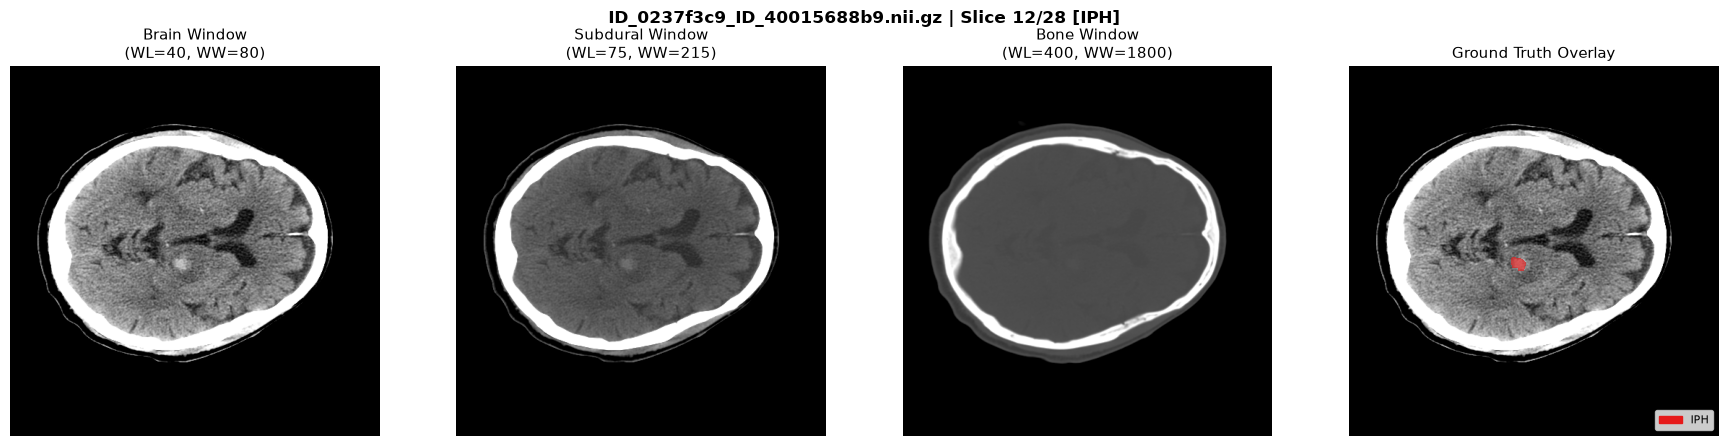

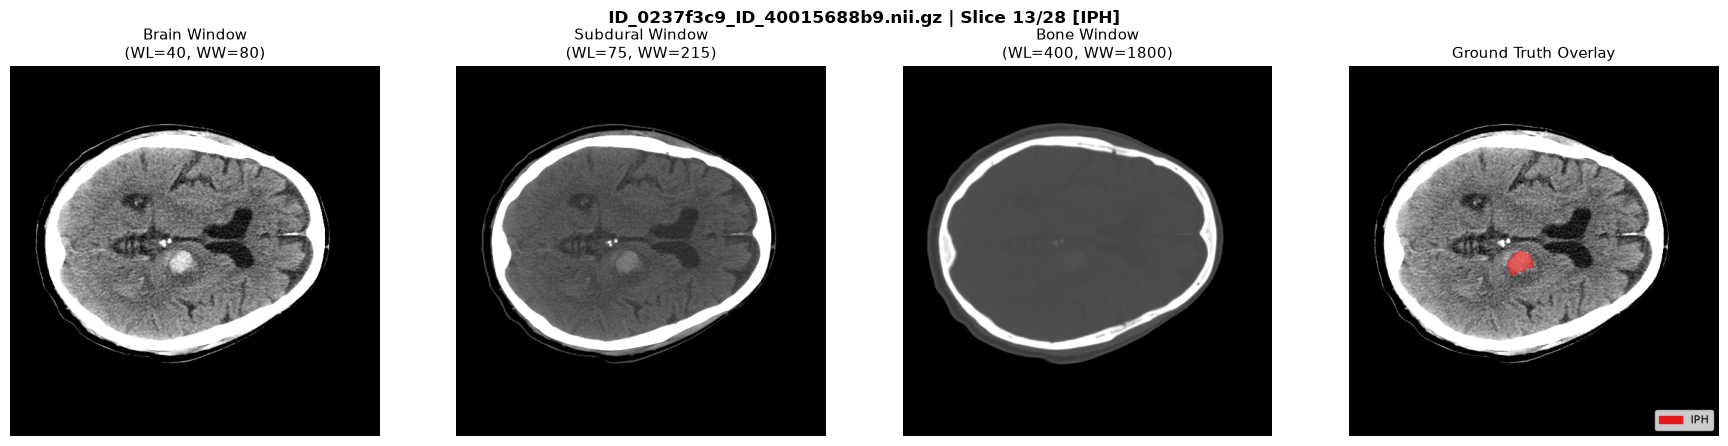

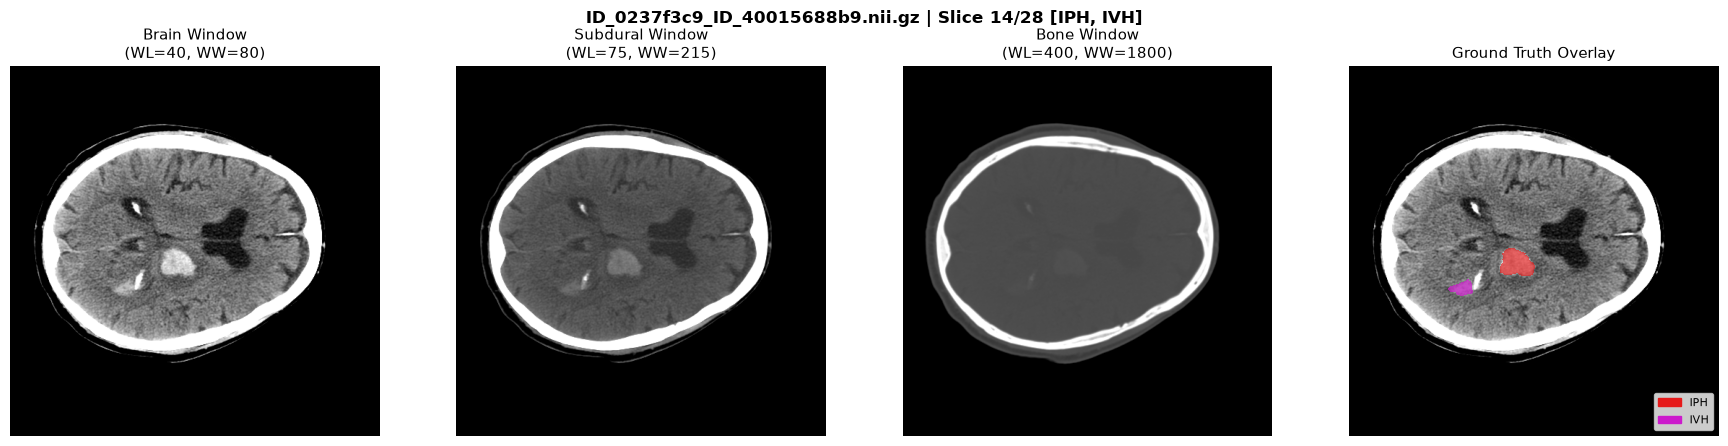

In [7]:
# =========================================================================
# 7. VISUAL DATASET INSPECTION
# =========================================================================
def render_slice_inspection(dataset, num_samples=3):
    count = 0
    for idx in range(len(dataset)):
        meta = dataset.slice_indices[idx]
        if meta["has_foreground"]:
            fname = meta["filename"]
            z = meta["slice_idx"]
            img_vol, gt_vol = dataset._load_volume(fname)
            slice_hu = img_vol[:, :, z].astype(np.float32)
            mask = gt_vol[:, :, z]

            windows = apply_3_windows(slice_hu)
            fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

            axes[0].imshow(windows[0], cmap="gray")
            axes[0].set_title("Brain Window\n(WL=40, WW=80)", fontsize=11)
            axes[0].axis("off")

            axes[1].imshow(windows[1], cmap="gray")
            axes[1].set_title("Subdural Window\n(WL=75, WW=215)", fontsize=11)
            axes[1].axis("off")

            axes[2].imshow(windows[2], cmap="gray")
            axes[2].set_title("Bone Window\n(WL=400, WW=1800)", fontsize=11)
            axes[2].axis("off")

            axes[3].imshow(windows[0], cmap="gray")
            axes[3].imshow(mask, cmap=OVERLAY_CMAP, vmin=0, vmax=5, interpolation="nearest")
            axes[3].set_title("Ground Truth Overlay", fontsize=11)
            axes[3].axis("off")

            # Legend
            present = np.unique(mask)
            patches = [mpatches.Patch(color=CLASS_COLORS[c][:3], label=TARGET_NAMES[c]) for c in range(1, 6) if c in present]
            if patches:
                axes[3].legend(handles=patches, loc="lower right", fontsize=8)

            classes_str = ", ".join([TARGET_NAMES[c] for c in meta["target_classes"] if c > 0])
            plt.suptitle(f"{fname} | Slice {z}/{meta['num_slices']} [{classes_str}]", fontsize=12, fontweight="bold")
            plt.tight_layout()
            save_path = os.path.join(OUTPUT_DIR, "figures", f"dataset_inspection_{count+1}.png")
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
            plt.show()

            count += 1
            if count >= num_samples:
                break

render_slice_inspection(train_dataset, num_samples=3)


## 8. DeepLabV3+ Model with ResNet34 & Dropout Verification

We instantiate DeepLabV3+ with:
- **ResNet34 Backbone** (ImageNet pretrained weights adapted for 9 input channels).
- **Decoder ASPP Dropout:** $p = 0.2$ (verified $\ge 0.2$ at startup).
- **`enable_mc_dropout()`:** Keeps BatchNorm frozen in evaluation mode while keeping Dropout layers stochastic for Monte Carlo uncertainty estimation.
- **Forward & Gradient Smoke Test:** Verifies that raw logits are finite and gradients flow to all 142 parameter tensors.


In [8]:
# =========================================================================
# 8. DEEPLABV3+ MODEL IMPLEMENTATION & VERIFICATION
# =========================================================================
def count_and_validate_dropout(model: nn.Module, min_prob: float = 0.2) -> List[Tuple[str, nn.Module, float]]:
    dropout_layers = []
    for name, module in model.named_modules():
        if isinstance(module, (nn.Dropout, nn.Dropout2d, nn.Dropout3d)):
            dropout_layers.append((name, module, float(module.p)))
            
    if len(dropout_layers) == 0:
        raise AssertionError("CRITICAL: No dropout layer found! Required for MC Dropout.")
    valid_prob = any(p >= min_prob for _, _, p in dropout_layers)
    if not valid_prob:
        raise AssertionError(f"CRITICAL: Found dropout layers but none have p >= {min_prob}!")
    return dropout_layers

def enable_mc_dropout(model: nn.Module) -> None:
    model.eval()  # Freeze BatchNorm running statistics
    for module in model.modules():
        if isinstance(module, (nn.Dropout, nn.Dropout2d, nn.Dropout3d)):
            module.train(True)

class DeepLabV3Plus25D(nn.Module):
    def __init__(self, encoder_name="resnet34", encoder_weights="imagenet", in_channels=9, num_classes=6, decoder_dropout=0.2):
        super().__init__()
        self.model = smp.DeepLabV3Plus(
            encoder_name=encoder_name,
            encoder_weights=encoder_weights,
            in_channels=in_channels,
            classes=num_classes,
            activation=None,  # Returns raw logits
            decoder_aspp_dropout=decoder_dropout,
        )
        self.dropouts = count_and_validate_dropout(self.model, min_prob=decoder_dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

# Instantiate & Verify
model = DeepLabV3Plus25D(
    encoder_name=ENCODER_NAME,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=IN_CHANNELS,
    num_classes=NUM_CLASSES,
    decoder_dropout=DECODER_DROPOUT,
).to(DEVICE)

print(f"[MODEL] DeepLabV3+ with {ENCODER_NAME} initialized successfully.")
print(f"[MODEL] Dropout layers verified ({len(model.dropouts)} active layer with p={model.dropouts[0][2]}).")

# Forward Pass & Gradient Verification Smoke Test
model.train()
dummy_x = torch.randn(2, IN_CHANNELS, 128, 128, device=DEVICE, requires_grad=True)
dummy_target = torch.randint(0, NUM_CLASSES, (2, 128, 128), device=DEVICE)
dummy_logits = model(dummy_x)
assert dummy_logits.shape == (2, NUM_CLASSES, 128, 128), "Mismatch in model output shape!"
assert torch.isfinite(dummy_logits).all(), "Logits contain NaNs or Infs!"

dummy_loss = F.cross_entropy(dummy_logits, dummy_target)
dummy_loss.backward()
assert dummy_x.grad is not None and torch.isfinite(dummy_x.grad).all(), "Gradient flow check failed!"
print(f"[VERIFIED] Forward pass output shape: {list(dummy_logits.shape)}")
print(f"[VERIFIED] Gradients active on all parameter tensors. Gradient check PASSED!")
model.zero_grad()


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

c:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\whate\.cache\huggingface\hub\models--smp-hub--resnet34.imagenet. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[MODEL] DeepLabV3+ with resnet34 initialized successfully.
[MODEL] Dropout layers verified (1 active layer with p=0.2).
[VERIFIED] Forward pass output shape: [2, 6, 128, 128]
[VERIFIED] Gradients active on all parameter tensors. Gradient check PASSED!


## 9. Imbalance-Aware Loss: Weighted CE + Multiclass Dice

Because the background class represents $>99.6\%$ of voxels:
1. **Class Frequencies** are computed strictly from the **training manifest only**.
2. **Capped Class Weights**: Inverse frequencies with square-root smoothing, capped at `MAX_CLASS_WEIGHT=25.0` to prevent gradient explosion on tiny lesions.
3. **Combined Objective**:
   $$\mathcal{L} = \alpha_{CE} \mathcal{L}_{CE}(\mathbf{w}) + \beta_{Dice} \mathcal{L}_{Dice}$$


In [9]:
# =========================================================================
# 9. LOSS FUNCTIONS & TRAINING-DERIVED CLASS WEIGHTS
# =========================================================================
def compute_class_weights_from_manifest(manifest_csv: str, dataset_dir: str, num_classes=6, power=0.5, max_w=25.0):
    df = pd.read_csv(manifest_csv)
    gt_dir = os.path.join(dataset_dir, "labeled", "ground_truths")
    pixel_counts = np.zeros(num_classes, dtype=np.int64)

    for fname in df["filename"]:
        gt_data = np.asanyarray(nib.load(os.path.join(gt_dir, fname)).dataobj)
        for raw_c, target_c in BHSD_TO_TARGET.items():
            pixel_counts[target_c] += np.sum(gt_data == raw_c)

    total_pixels = pixel_counts.sum()
    freqs = np.maximum(pixel_counts / float(total_pixels), 1e-8)
    raw_weights = (1.0 / freqs) ** power
    weights = np.clip(raw_weights / raw_weights[0], 1.0, max_w)

    print("=== TRAINING DATASET PIXEL COUNTS & CLASS WEIGHTS ===")
    for c in range(num_classes):
        print(f"  Class {c} ({TARGET_NAMES[c]}): {pixel_counts[c]:,} px ({freqs[c]*100:.4f}%) | Weight: {weights[c]:.2f}")
    return torch.tensor(weights, dtype=torch.float32)

class MulticlassDiceLoss(nn.Module):
    def __init__(self, num_classes: int = 6, smooth: float = 1.0):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)
        targets_oh = F.one_hot(targets, num_classes=self.num_classes).permute(0, 3, 1, 2).float()

        dice_losses = []
        for c in range(self.num_classes):
            p_c = probs[:, c, :, :].contiguous().view(-1)
            t_c = targets_oh[:, c, :, :].contiguous().view(-1)
            inter = (p_c * t_c).sum()
            card = p_c.sum() + t_c.sum()
            dice = (2.0 * inter + self.smooth) / (card + self.smooth)
            dice_losses.append(1.0 - dice)
        return torch.stack(dice_losses).mean()

class CombinedLoss(nn.Module):
    def __init__(self, class_weights: torch.Tensor, alpha_ce=1.0, beta_dice=1.0, num_classes=6):
        super().__init__()
        self.alpha_ce = alpha_ce
        self.beta_dice = beta_dice
        self.ce = nn.CrossEntropyLoss(weight=class_weights)
        self.dice = MulticlassDiceLoss(num_classes=num_classes)

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        return self.alpha_ce * self.ce(logits, targets) + self.beta_dice * self.dice(logits, targets)

class_weights = compute_class_weights_from_manifest(
    TRAIN_MANIFEST, DATASET_DIR, num_classes=NUM_CLASSES, power=WEIGHT_POWER, max_w=MAX_CLASS_WEIGHT
).to(DEVICE)

loss_fn = CombinedLoss(class_weights=class_weights, alpha_ce=ALPHA_CE, beta_dice=BETA_DICE, num_classes=NUM_CLASSES).to(DEVICE)
print("[LOSS] Combined Weighted-CE + Soft Multiclass Dice Loss configured.")


=== TRAINING DATASET PIXEL COUNTS & CLASS WEIGHTS ===
  Class 0 (Background): 1,176,788,380 px (99.6911%) | Weight: 1.00
  Class 1 (IPH): 1,533,773 px (0.1299%) | Weight: 25.00
  Class 2 (SAH): 521,874 px (0.0442%) | Weight: 25.00
  Class 3 (EDH): 234,378 px (0.0199%) | Weight: 25.00
  Class 4 (SDH): 838,105 px (0.0710%) | Weight: 25.00
  Class 5 (IVH): 517,922 px (0.0439%) | Weight: 25.00
[LOSS] Combined Weighted-CE + Soft Multiclass Dice Loss configured.


## 10. Rigorous Multi-Class Evaluation Metrics

We compute:
- **Per-Class Metrics:** Dice, IoU (Jaccard), Precision, and Recall for all 6 classes.
- **Validation Macro Dice:** Arithmetic mean across the **5 hemorrhage classes only** (excluding background).
- **Confusion Matrix:** $6 \times 6$ pixel confusion matrix tracking inter-class confusion (e.g. IPH vs IVH).


In [10]:
# =========================================================================
# 10. EVALUATION METRICS METER
# =========================================================================
class SegmentationMetricsMeter:
    def __init__(self, num_classes: int = 6):
        self.num_classes = num_classes
        self.reset()

    def reset(self):
        self.cm = np.zeros((self.num_classes, self.num_classes), dtype=np.int64)

    def update(self, preds: np.ndarray, targets: np.ndarray):
        p_flat = preds.ravel()
        t_flat = targets.ravel()
        valid = (t_flat >= 0) & (t_flat < self.num_classes) & (p_flat >= 0) & (p_flat < self.num_classes)
        indices = t_flat[valid] * self.num_classes + p_flat[valid]
        bincount = np.bincount(indices, minlength=self.num_classes ** 2)
        self.cm += bincount.reshape((self.num_classes, self.num_classes))

    def compute(self, eps: float = 1e-7) -> Dict[str, Any]:
        cm = self.cm
        per_class_dice = {}
        per_class_iou = {}
        per_class_precision = {}
        per_class_recall = {}
        fg_dices, fg_ious = [], []

        for c in range(self.num_classes):
            name = TARGET_NAMES[c]
            tp = float(cm[c, c])
            fp = float(cm[:, c].sum() - tp)
            fn = float(cm[c, :].sum() - tp)

            dice = (2.0 * tp) / (2.0 * tp + fp + fn + eps)
            iou = tp / (tp + fp + fn + eps)
            precision = tp / (tp + fp + eps)
            recall = tp / (tp + fn + eps)

            per_class_dice[name] = dice
            per_class_iou[name] = iou
            per_class_precision[name] = precision
            per_class_recall[name] = recall

            if c > 0:  # 5 hemorrhage subtypes
                fg_dices.append(dice)
                fg_ious.append(iou)

        return {
            "per_class_dice": per_class_dice,
            "per_class_iou": per_class_iou,
            "per_class_precision": per_class_precision,
            "per_class_recall": per_class_recall,
            "macro_dice": float(np.mean(fg_dices)),
            "macro_iou": float(np.mean(fg_ious)),
            "confusion_matrix": cm,
        }

print("[METRICS] SegmentationMetricsMeter initialized.")


[METRICS] SegmentationMetricsMeter initialized.


## 11. Training & Validation Engine

Key Training Safeguards:
- **Automatic Mixed Precision (`torch.amp`)** for accelerated tensor core performance.
- **Gradient Clipping** to bound gradient norms.
- **Cosine Annealing Learning Rate Schedule**.
- **Model Checkpointing**: The `best_model.pth` is saved **strictly based on Validation Macro Dice across the 5 hemorrhage classes**, completely disregarding overall pixel accuracy.


In [11]:
# =========================================================================
# 11. TRAINING ENGINE WITH MACRO DICE CHECKPOINTING
# =========================================================================
class Trainer:
    def __init__(self, model, train_loader, val_loader, loss_fn, optimizer, scheduler, device, output_dir, use_amp=True, grad_clip=1.0, patience=10):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.loss_fn = loss_fn.to(device)
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.device = device
        self.output_dir = output_dir
        self.use_amp = use_amp and (device.type == "cuda")
        self.grad_clip = grad_clip
        self.patience = patience
        self.scaler = torch.amp.GradScaler("cuda", enabled=self.use_amp)

        self.best_macro_dice = -1.0
        self.best_epoch = -1
        self.history = {
            "epoch": [], "train_loss": [], "val_loss": [], "val_macro_dice": [], "val_macro_iou": [], "lr": []
        }
        for name in TARGET_NAMES:
            self.history[f"val_dice_{name}"] = []
            self.history[f"val_recall_{name}"] = []

    def train_epoch(self, epoch: int) -> float:
        self.model.train()
        total_loss = 0.0
        pbar = tqdm(self.train_loader, desc=f"Epoch {epoch:02d} [Train]", leave=False)

        for images, masks, _ in pbar:
            images = images.to(self.device, non_blocking=True)
            masks = masks.to(self.device, non_blocking=True)
            self.optimizer.zero_grad()

            with torch.amp.autocast(device_type=self.device.type, enabled=self.use_amp):
                logits = self.model(images)
                loss = self.loss_fn(logits, masks)

            self.scaler.scale(loss).backward()
            if self.grad_clip > 0:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)

            self.scaler.step(self.optimizer)
            self.scaler.update()

            batch_loss = loss.item()
            total_loss += batch_loss
            pbar.set_postfix({"loss": f"{batch_loss:.4f}"})

        return total_loss / max(1, len(self.train_loader))

    @torch.no_grad()
    def validate(self, epoch: int) -> Tuple[float, Dict[str, Any]]:
        self.model.eval()
        total_loss = 0.0
        meter = SegmentationMetricsMeter(num_classes=6)
        pbar = tqdm(self.val_loader, desc=f"Epoch {epoch:02d} [Val]", leave=False)

        for images, masks, _ in pbar:
            images = images.to(self.device, non_blocking=True)
            masks = masks.to(self.device, non_blocking=True)

            with torch.amp.autocast(device_type=self.device.type, enabled=self.use_amp):
                logits = self.model(images)
                loss = self.loss_fn(logits, masks)

            total_loss += loss.item()
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            meter.update(preds, masks.cpu().numpy())

        metrics = meter.compute()
        metrics["val_loss"] = total_loss / max(1, len(self.val_loader))
        return metrics["val_loss"], metrics

    def train(self, num_epochs: int):
        print(f"\n[TRAINING] Beginning training for {num_epochs} epochs on {self.device} (Mixed Precision: {self.use_amp})...")
        epochs_no_improve = 0

        for epoch in range(1, num_epochs + 1):
            t0 = time.time()
            train_loss = self.train_epoch(epoch)
            val_loss, val_metrics = self.validate(epoch)
            elapsed = time.time() - t0

            if self.scheduler:
                self.scheduler.step()

            macro_dice = val_metrics["macro_dice"]
            current_lr = self.optimizer.param_groups[0]["lr"]

            # Record history
            self.history["epoch"].append(epoch)
            self.history["train_loss"].append(train_loss)
            self.history["val_loss"].append(val_loss)
            self.history["val_macro_dice"].append(macro_dice)
            self.history["val_macro_iou"].append(val_metrics["macro_iou"])
            self.history["lr"].append(current_lr)

            for name in TARGET_NAMES:
                self.history[f"val_dice_{name}"].append(val_metrics["per_class_dice"][name])
                self.history[f"val_recall_{name}"].append(val_metrics["per_class_recall"][name])

            print(f"Epoch {epoch:02d}/{num_epochs:02d} [{elapsed:.1f}s] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro Dice: {macro_dice:.4f} | LR: {current_lr:.2e}")
            per_class_str = ", ".join([f"{name}: {val_metrics['per_class_dice'][name]:.3f}" for name in TARGET_NAMES[1:]])
            print(f"  --> Val Dice [{per_class_str}]")

            # Checkpoint saving strictly by macro Dice across 5 hemorrhage classes
            if macro_dice > self.best_macro_dice:
                self.best_macro_dice = macro_dice
                self.best_epoch = epoch
                epochs_no_improve = 0
                ckpt_path = os.path.join(self.output_dir, "checkpoints", "best_model.pth")
                torch.save({
                    "epoch": epoch,
                    "model_state_dict": self.model.state_dict(),
                    "best_macro_dice": self.best_macro_dice,
                    "metrics": val_metrics,
                }, ckpt_path)
                print(f"  >>> Best Checkpoint Saved! (Macro Dice: {macro_dice:.4f} at epoch {epoch})")
            else:
                epochs_no_improve += 1

            # Save latest checkpoint & history CSV
            latest_path = os.path.join(self.output_dir, "checkpoints", "latest_model.pth")
            torch.save({"epoch": epoch, "model_state_dict": self.model.state_dict(), "metrics": val_metrics}, latest_path)

            history_df = pd.DataFrame(self.history)
            history_df.to_csv(os.path.join(self.output_dir, "metrics", "training_history.csv"), index=False)

            if epochs_no_improve >= self.patience:
                print(f"\n[EARLY STOPPING] Triggered after {epochs_no_improve} epochs without Macro Dice improvement.")
                break

        print(f"\n[COMPLETE] Training finished! Best Macro Dice: {self.best_macro_dice:.4f} achieved at epoch {self.best_epoch}")
        return self.history


## 12. Execute Model Training

Run the cell below to train the 2.5D DeepLabV3+ model across the configured number of epochs.


In [12]:
# =========================================================================
# 12. RUN TRAINING PIPELINE
# =========================================================================
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=MIN_LR)

trainer = Trainer(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    scheduler=scheduler,
    device=DEVICE,
    output_dir=OUTPUT_DIR,
    use_amp=USE_AMP,
    grad_clip=GRAD_CLIP_NORM,
    patience=EARLY_STOPPING_PATIENCE,
)

# Start training
history = trainer.train(num_epochs=NUM_EPOCHS)



[TRAINING] Beginning training for 35 epochs on cuda (Mixed Precision: True)...


Epoch 01 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch 01 [Val]:   0%|          | 0/116 [00:00<?, ?it/s]

Epoch 01/35 [802.7s] | Train Loss: 1.0789 | Val Loss: 0.9076 | Val Macro Dice: 0.2532 | LR: 2.99e-04
  --> Val Dice [IPH: 0.666, SAH: 0.115, EDH: 0.000, SDH: 0.082, IVH: 0.403]
  >>> Best Checkpoint Saved! (Macro Dice: 0.2532 at epoch 1)


Epoch 02 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

...

Epoch 30 [Val]:   0%|          | 0/116 [00:00<?, ?it/s]

Epoch 30/35 [778.2s] | Train Loss: 0.1746 | Val Loss: 0.6041 | Val Macro Dice: 0.4135 | LR: 2.44e-05
  --> Val Dice [IPH: 0.795, SAH: 0.330, EDH: 0.000, SDH: 0.284, IVH: 0.660]


Epoch 31 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

Epoch 31 [Val]:   0%|          | 0/116 [00:00<?, ?it/s]

Epoch 31/35 [778.7s] | Train Loss: 0.1752 | Val Loss: 0.6204 | Val Macro Dice: 0.4001 | LR: 1.92e-05
  --> Val Dice [IPH: 0.779, SAH: 0.331, EDH: 0.000, SDH: 0.235, IVH: 0.656]

[EARLY STOPPING] Triggered after 12 epochs without Macro Dice improvement.

[COMPLETE] Training finished! Best Macro Dice: 0.4534 achieved at epoch 19


## 13. Comprehensive Evaluation on Held-Out Validation Set

The cells below load the **best saved checkpoint** and evaluate the complete held-out validation set (28 volumes, 924 slices):
1. **Loss & Dice Curves**
2. **Metrics Table (Dice, IoU, Precision, Recall per class)**
3. **Normalized 6-Class Pixel Confusion Matrix**
4. **Side-by-Side Visual Predictions vs Ground Truth Overlays**


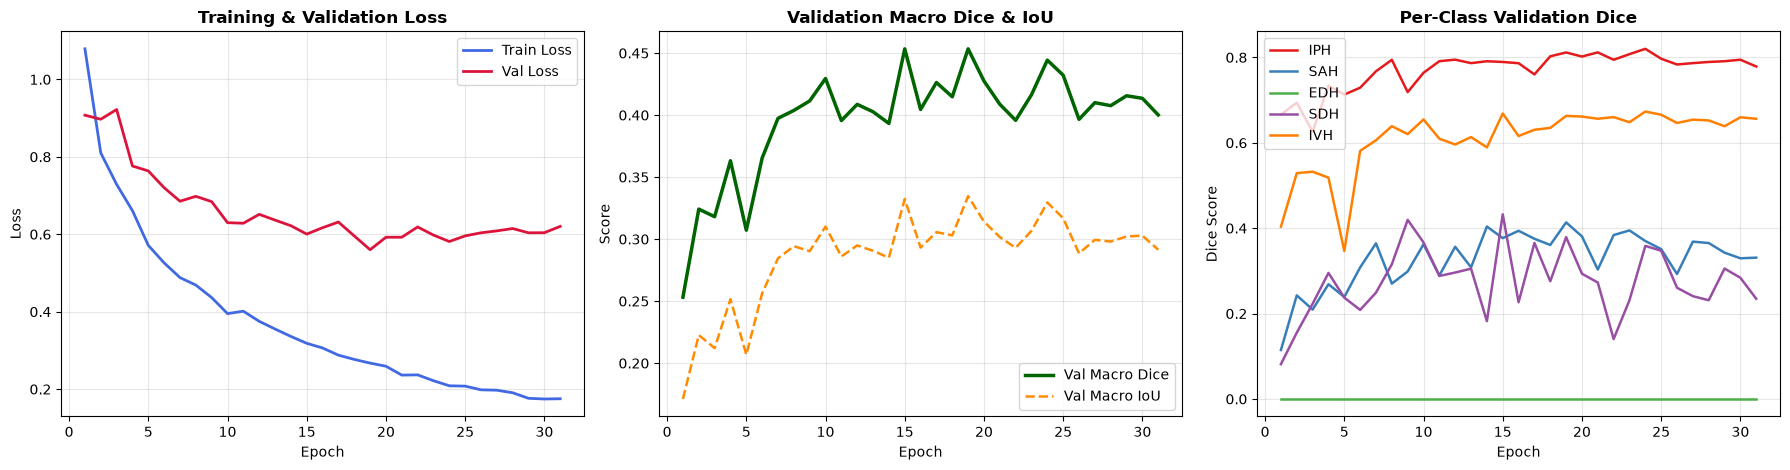

[SAVED] Training curves saved to: c:\Users\whate\Documents\Brain CT Hemorrage Detection\outputs\figures\training_curves.png


In [13]:
# =========================================================================
# 13. PLOT TRAINING & VALIDATION CURVES
# =========================================================================
history_csv = os.path.join(OUTPUT_DIR, "metrics", "training_history.csv")
if os.path.exists(history_csv):
    df_hist = pd.read_csv(history_csv)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

    # Loss
    axes[0].plot(df_hist["epoch"], df_hist["train_loss"], label="Train Loss", color="royalblue", lw=2)
    axes[0].plot(df_hist["epoch"], df_hist["val_loss"], label="Val Loss", color="crimson", lw=2)
    axes[0].set_title("Training & Validation Loss", fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    # Macro Dice & IoU
    axes[1].plot(df_hist["epoch"], df_hist["val_macro_dice"], label="Val Macro Dice", color="darkgreen", lw=2.5)
    axes[1].plot(df_hist["epoch"], df_hist["val_macro_iou"], label="Val Macro IoU", color="darkorange", lw=1.8, linestyle="--")
    axes[1].set_title("Validation Macro Dice & IoU", fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    # Per-Class Dice
    palette = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00"]
    for i, name in enumerate(TARGET_NAMES[1:]):
        col = f"val_dice_{name}"
        if col in df_hist:
            axes[2].plot(df_hist["epoch"], df_hist[col], label=name, lw=1.8, color=palette[i % len(palette)])
    axes[2].set_title("Per-Class Validation Dice", fontweight="bold")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Dice Score")
    axes[2].grid(True, alpha=0.3)
    axes[2].legend()

    plt.tight_layout()
    curve_path = os.path.join(OUTPUT_DIR, "figures", "training_curves.png")
    plt.savefig(curve_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[SAVED] Training curves saved to: {curve_path}")


Loading best checkpoint from c:\Users\whate\Documents\Brain CT Hemorrage Detection\outputs\checkpoints\best_model.pth...


Evaluating Held-out Validation Set:   0%|          | 0/116 [00:00<?, ?it/s]


HELD-OUT VALIDATION SET EVALUATION RESULTS (28 Volumes, 924 Slices)


,Class ID,Hemorrhage Class,Dice,IoU,Precision,Recall
0,0,Background,0.9991,0.9982,0.9991,0.9992
1,1,IPH,0.8115,0.6828,0.7892,0.8351
2,2,SAH,0.4136,0.2607,0.3875,0.4435
3,3,EDH,0.0000,0.0000,0.0000,0.0000
4,4,SDH,0.3790,0.2338,0.4984,0.3058
5,5,IVH,0.6630,0.4959,0.6689,0.6572



** Macro Dice across 5 Hemorrhage Classes (excl. BG) : 0.4534
** Macro IoU across 5 Hemorrhage Classes (excl. BG)  : 0.3347
[SAVED] Metrics table saved to: c:\Users\whate\Documents\Brain CT Hemorrage Detection\outputs\metrics\validation_metrics.csv


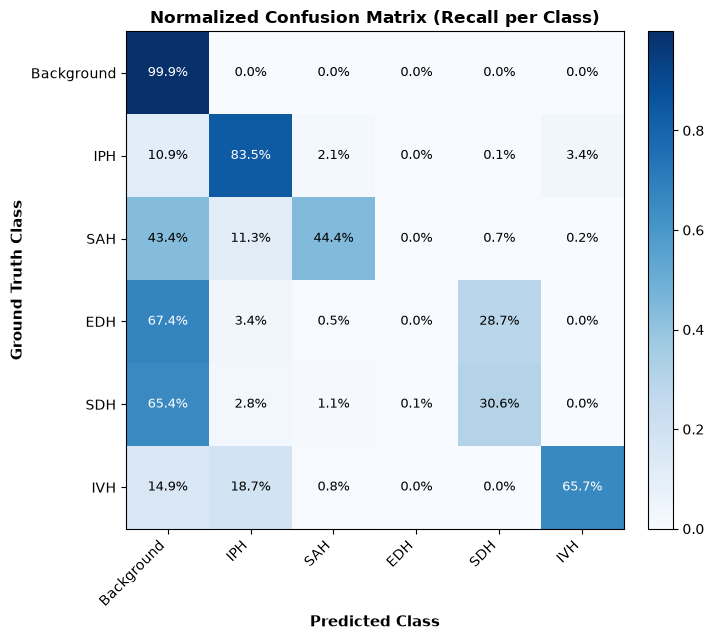

[SAVED] Confusion matrix saved to: c:\Users\whate\Documents\Brain CT Hemorrage Detection\outputs\figures\confusion_matrix.png


In [14]:
# =========================================================================
# 14. EVALUATE BEST CHECKPOINT ON VALIDATION SET
# =========================================================================
best_ckpt_path = os.path.join(OUTPUT_DIR, "checkpoints", "best_model.pth")
assert os.path.exists(best_ckpt_path), f"Checkpoint not found at {best_ckpt_path}!"

print(f"Loading best checkpoint from {best_ckpt_path}...")
ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

meter = SegmentationMetricsMeter(num_classes=6)
with torch.no_grad():
    for images, masks, _ in tqdm(val_loader, desc="Evaluating Held-out Validation Set"):
        images = images.to(DEVICE)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        meter.update(preds, masks.numpy())

metrics = meter.compute()

# Format & Print Metrics Table
print("\n" + "="*70)
print("HELD-OUT VALIDATION SET EVALUATION RESULTS (28 Volumes, 924 Slices)")
print("="*70)
metrics_rows = []
for c in range(6):
    name = TARGET_NAMES[c]
    d = metrics["per_class_dice"][name]
    j = metrics["per_class_iou"][name]
    p = metrics["per_class_precision"][name]
    r = metrics["per_class_recall"][name]
    metrics_rows.append({"Class ID": c, "Hemorrhage Class": name, "Dice": d, "IoU": j, "Precision": p, "Recall": r})

results_df = pd.DataFrame(metrics_rows)
display(results_df.style.format({"Dice": "{:.4f}", "IoU": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}"}))

print(f"\n** Macro Dice across 5 Hemorrhage Classes (excl. BG) : {metrics['macro_dice']:.4f}")
print(f"** Macro IoU across 5 Hemorrhage Classes (excl. BG)  : {metrics['macro_iou']:.4f}")

# Save CSV
metrics_csv_path = os.path.join(OUTPUT_DIR, "metrics", "validation_metrics.csv")
results_df.to_csv(metrics_csv_path, index=False)
print(f"[SAVED] Metrics table saved to: {metrics_csv_path}")

# Plot Confusion Matrix
cm = metrics["confusion_matrix"]
row_sums = cm.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
cm_norm = cm.astype(np.float64) / row_sums

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_norm, cmap="Blues", interpolation="nearest")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax.set_xticks(range(6))
ax.set_yticks(range(6))
ax.set_xticklabels(TARGET_NAMES, rotation=45, ha="right", fontsize=10)
ax.set_yticklabels(TARGET_NAMES, fontsize=10)
ax.set_xlabel("Predicted Class", fontweight="bold", fontsize=11)
ax.set_ylabel("Ground Truth Class", fontweight="bold", fontsize=11)
ax.set_title("Normalized Confusion Matrix (Recall per Class)", fontweight="bold", fontsize=12)

thresh = cm_norm.max() / 2.0
for i in range(6):
    for j in range(6):
        val = cm_norm[i, j]
        ax.text(j, i, f"{val*100:.1f}%", ha="center", va="center", color="white" if val > thresh else "black", fontsize=9)

plt.tight_layout()
cm_path = os.path.join(OUTPUT_DIR, "figures", "confusion_matrix.png")
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"[SAVED] Confusion matrix saved to: {cm_path}")


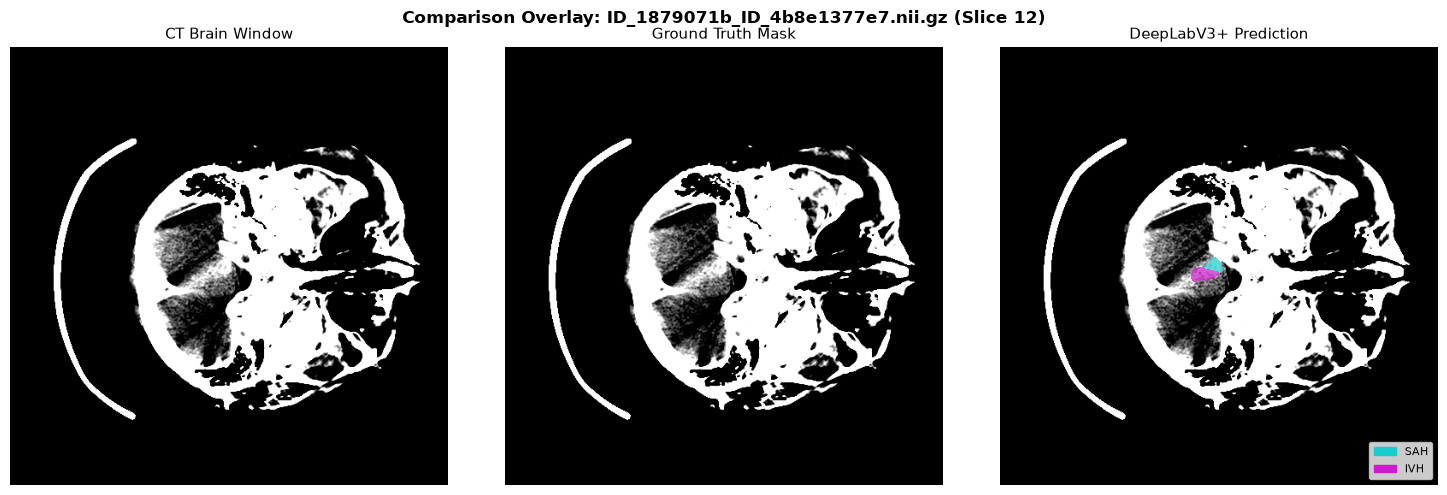

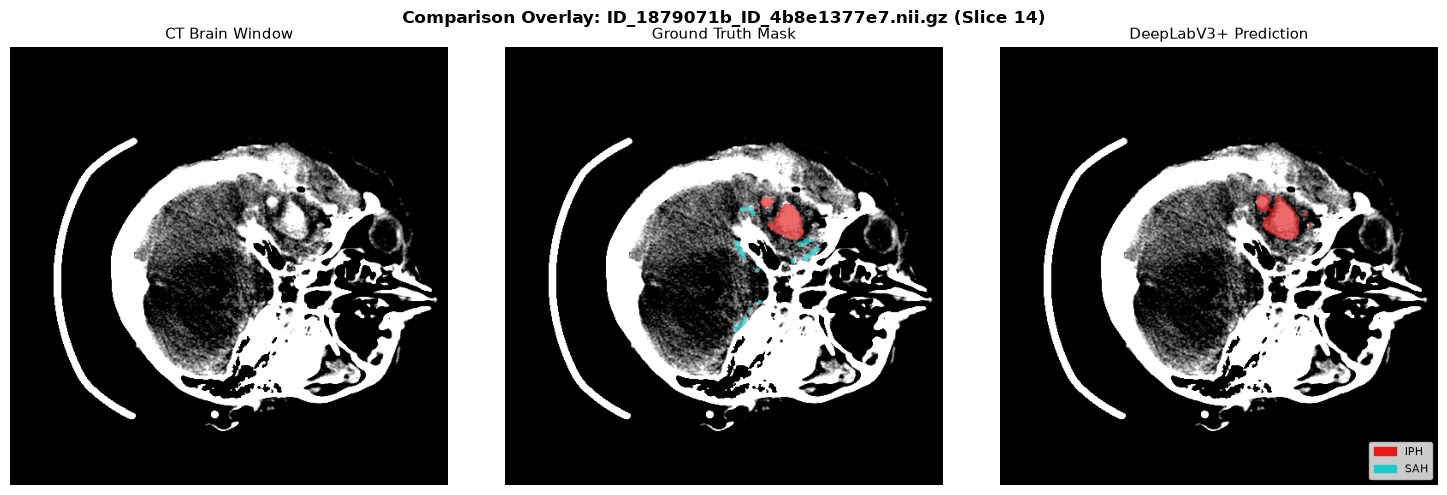

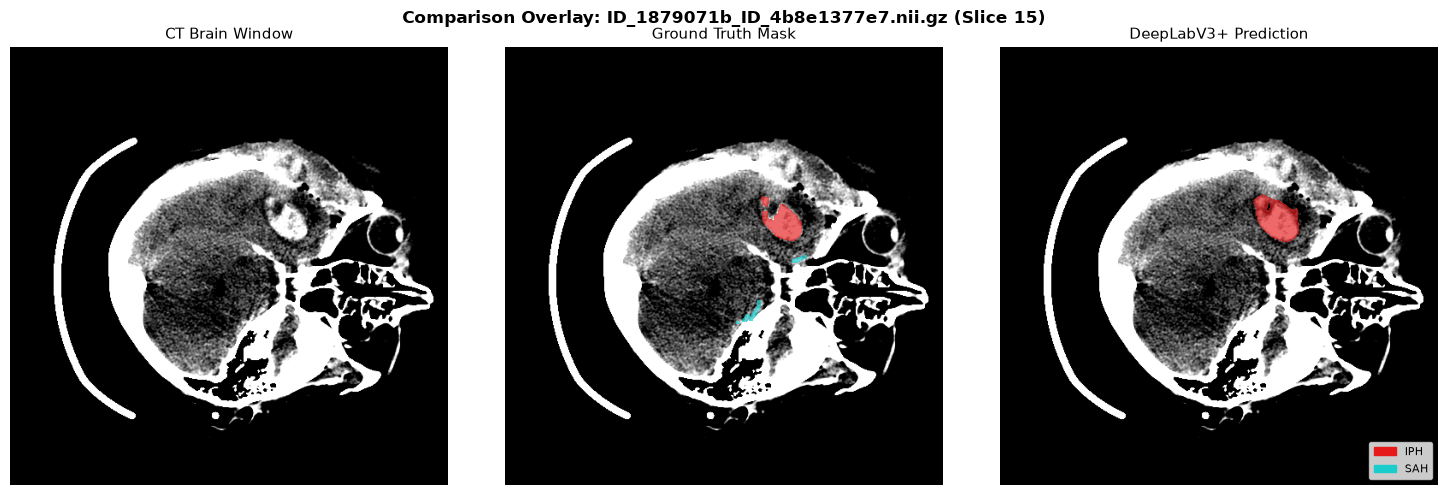

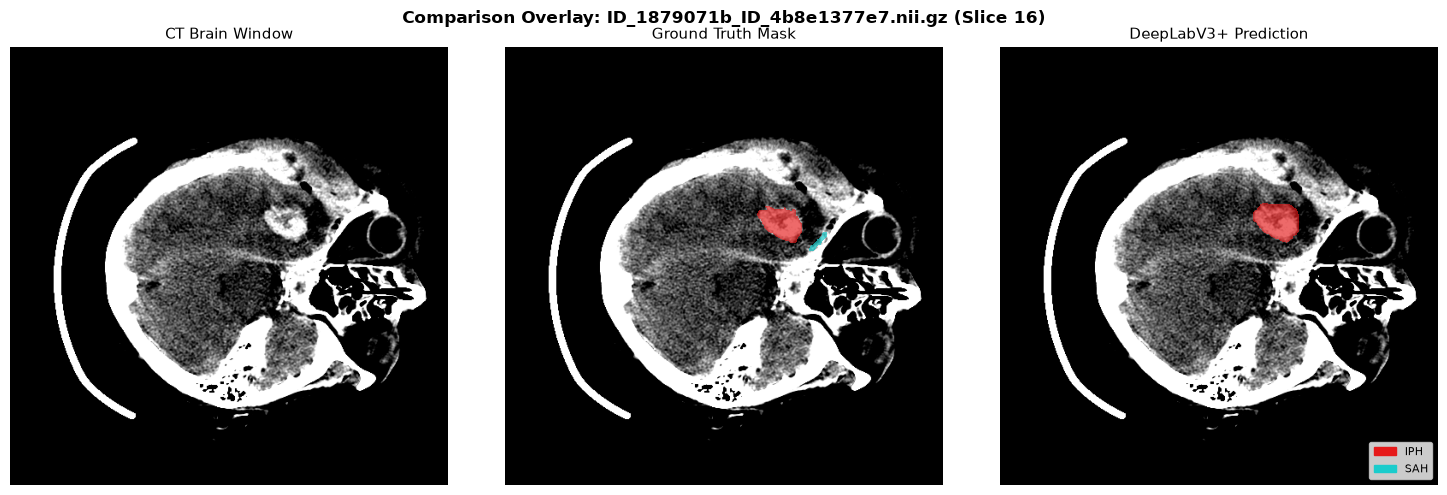

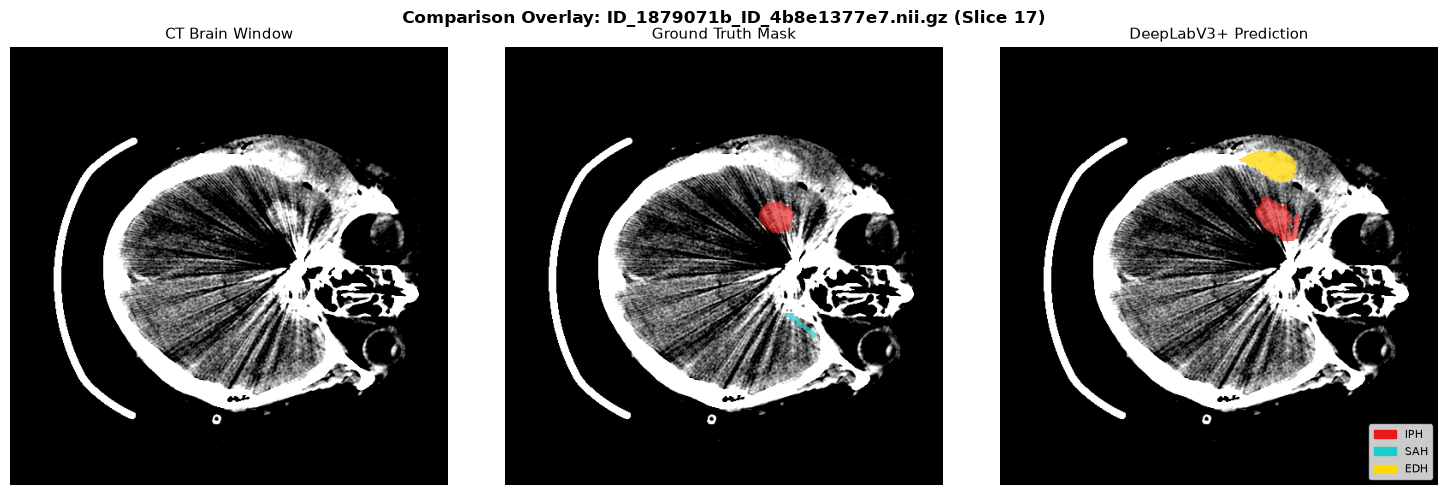

In [15]:
# =========================================================================
# 15. VISUAL SUCCESS & FAILURE OVERLAYS (GT vs DEEPLABV3+ PREDICTIONS)
# =========================================================================
model.eval()
saved_count = 0
max_visualizations = 5

for images, masks, sample_info in val_loader:
    images = images.to(DEVICE)
    with torch.no_grad():
        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
    preds = torch.argmax(logits, dim=1).cpu().numpy()
    masks_np = masks.numpy()

    for b in range(images.shape[0]):
        gt_slice = masks_np[b]
        pred_slice = preds[b]

        # Only display slices where hemorrhage is present in GT or Prediction
        if (gt_slice > 0).any() or (pred_slice > 0).any():
            saved_count += 1
            # Middle slice Brain window is channel 3
            brain_win = images[b, 3].cpu().numpy() * 0.485 + 0.485
            brain_win = np.clip(brain_win, 0.0, 1.0)

            fig, axes = plt.subplots(1, 3, figsize=(15, 5))
            axes[0].imshow(brain_win, cmap="gray")
            axes[0].set_title("CT Brain Window", fontsize=11)
            axes[0].axis("off")

            axes[1].imshow(brain_win, cmap="gray")
            axes[1].imshow(gt_slice, cmap=OVERLAY_CMAP, vmin=0, vmax=5, interpolation="nearest")
            axes[1].set_title("Ground Truth Mask", fontsize=11)
            axes[1].axis("off")

            axes[2].imshow(brain_win, cmap="gray")
            axes[2].imshow(pred_slice, cmap=OVERLAY_CMAP, vmin=0, vmax=5, interpolation="nearest")
            axes[2].set_title("DeepLabV3+ Prediction", fontsize=11)
            axes[2].axis("off")

            # Add Legend
            active_classes = np.union1d(np.unique(gt_slice), np.unique(pred_slice))
            patches = [mpatches.Patch(color=CLASS_COLORS[c][:3], label=TARGET_NAMES[c]) for c in range(1, 6) if c in active_classes]
            if patches:
                axes[2].legend(handles=patches, loc="lower right", fontsize=8)

            fname = sample_info["filename"][b]
            z = int(sample_info["slice_idx"][b])
            plt.suptitle(f"Comparison Overlay: {fname} (Slice {z})", fontsize=12, fontweight="bold")
            plt.tight_layout()
            overlay_file = os.path.join(OUTPUT_DIR, "figures", f"prediction_overlay_{saved_count}.png")
            plt.savefig(overlay_file, dpi=150, bbox_inches="tight")
            plt.show()

            if saved_count >= max_visualizations:
                break
    if saved_count >= max_visualizations:
        break


## 14. Summary & Readiness for Active Learning

### Key Pipeline Milestones Accomplished:
1. **Zero Patient & Volume Leakage:** Stratified 134 train, 28 val, 30 dev holdout volumes with multi-scan patient isolation.
2. **Explicit Label Mapping:** Complete alignment between BHSD raw annotation values and the 6 target clinical hemorrhage categories.
3. **Multi-Window 2.5D CT Input:** 9 input channels combining 3 consecutive slices $\times$ Brain, Subdural, and Bone windows.
4. **DeepLabV3+ with MC Dropout:** ResNet34 encoder with ASPP dropout $p \ge 0.2$ and `enable_mc_dropout()` utility.
5. **Class Imbalance Defense:** Training-derived class weighting combined with minority slice oversampling.
6. **Honest Evaluation:** Model selection strictly governed by **Validation Macro Dice across the 5 hemorrhage classes** (excluding background).

All model weights, metrics CSV files, training history, and comparison plots are saved in `outputs/`.
